# Laborator: Generator de text caracter-cu-caracter cu LSTM

## Obiectivele laboratorului

La finalul acestui laborator vei sti sa:

1. incarci si sa cureti un corpus de text;
2. construiesti un vocabular la nivel de caracter;
3. transformi textul in secvente de antrenare (X, y);
4. construiesti un model LSTM cu Keras;
5. antrenezi modelul si sa urmaresti evolutia pierderii;
6. generezi text nou pornind de la un seed, folosind temperatura;
7. salvezi si sa reincarci modelul antrenat.

## Corpusul folosit

Folosim scrierile lui Friedrich Nietzsche, traduse in engleza, disponibile la:

`https://s3.amazonaws.com/text-datasets/nietzsche.txt`

Fisierul trebuie sa fie deja descarcat in folderul `./data` din directorul proiectului, sub numele `nietzsche.txt`.

Structura proiectului:

```text
proiect/
├── data/
│   └── nietzsche.txt
└── laborator_lstm_text_generation.ipynb
```

## Cerinte tehnice

- Python 3.9+
- TensorFlow 2.x
- NumPy
- Matplotlib (optional, pentru grafice)

Instalare:

```bash
pip install tensorflow numpy matplotlib
```

> **Nota:** antrenarea unui LSTM este costisitoare computational. Se recomanda rularea pe GPU (de exemplu Google Colab cu runtime GPU).

## Pasul 1: Importul bibliotecilor

Importam bibliotecile necesare. Vom folosi:

- `numpy` pentru operatii cu tablouri multidimensionale;
- `tensorflow` si `keras` pentru construirea si antrenarea modelului;
- `random` pentru alegerea seed-urilor;
- `os` pentru verificarea existentei fisierului;
- `matplotlib` pentru vizualizarea curbei de pierdere.

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("Versiune TensorFlow:", tf.__version__)
print("GPU disponibil:", len(tf.config.list_physical_devices("GPU")) > 0)

I0000 00:00:1789891934.394235 1841396 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1789891934.896346 1841396 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1789891938.234464 1841396 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Versiune TensorFlow: 2.21.0
GPU disponibil: False


E0000 00:00:1789891938.882862 1841396 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## Pasul 2: Incarcarea corpusului

Citim fisierul `./data/nietzsche.txt` in memorie, in format UTF-8.

Verificam mai intai ca fisierul exista, apoi afisam:

- numarul total de caractere;
- primele 500 de caractere, ca sa ne facem o idee despre continut.

In [2]:
CORPUS_PATH = os.path.join("data", "nietzsche.txt")

if not os.path.exists(CORPUS_PATH):
    raise FileNotFoundError(
        f"Fisierul {CORPUS_PATH} nu a fost gasit. "
        "Descarca-l de la https://s3.amazonaws.com/text-datasets/nietzsche.txt "
        "si plaseaza-l in folderul ./data."
    )

with open(CORPUS_PATH, "r", encoding="utf-8") as f:
    text = f.read()

print(f"Numar total de caractere: {len(text):,}")
print("-" * 60)
print(text[:500])

Numar total de caractere: 600,893
------------------------------------------------------------
PREFACE


SUPPOSING that Truth is a woman--what then? Is there not ground
for suspecting that all philosophers, in so far as they have been
dogmatists, have failed to understand women--that the terrible
seriousness and clumsy importunity with which they have usually paid
their addresses to Truth, have been unskilled and unseemly methods for
winning a woman? Certainly she has never allowed herself to be won; and
at present every kind of dogma stands with sad and discouraged mien--IF,
indeed, it s


## Pasul 3: Curatarea textului

Corpusul brut contine caractere care nu ajuta la invatare si care maresc inutil vocabularul:

- treceri la linie noua (`\n`) si retur de carucior (`\r`);
- spatii multiple consecutive;
- caractere non-ASCII (accente, ghilimele speciale, liniute lungi).

Decizii de preprocesare:

1. convertim tot textul la litere mici (lowercase) — reduce vocabularul la jumatate;
2. inlocuim trecerile la linie noua cu un spatiu, pentru afisare mai curata a textului generat;
3. eliminam caracterele non-ASCII;
4. normalizam spatiile multiple.

> **Atentie:** daca pastram `\n` in corpus, modelul va invata si structura pe paragrafe, dar textul generat va fi mai greu de citit in consola. Pentru laborator alegem varianta simplificata.

In [3]:
def clean_text(raw_text: str) -> str:
    """Curata corpusul: lowercase, fara newline, doar ASCII, spatii normalizate."""
    cleaned = raw_text.lower()
    cleaned = cleaned.replace("\n", " ").replace("\r", " ")
    cleaned = "".join(ch for ch in cleaned if ord(ch) < 128)
    cleaned = " ".join(cleaned.split())
    return cleaned


text = clean_text(text)

print(f"Numar de caractere dupa curatare: {len(text):,}")
print("-" * 60)
print(text[:500])

Numar de caractere dupa curatare: 598,853
------------------------------------------------------------
preface supposing that truth is a woman--what then? is there not ground for suspecting that all philosophers, in so far as they have been dogmatists, have failed to understand women--that the terrible seriousness and clumsy importunity with which they have usually paid their addresses to truth, have been unskilled and unseemly methods for winning a woman? certainly she has never allowed herself to be won; and at present every kind of dogma stands with sad and discouraged mien--if, indeed, it sta


## Pasul 4: Construirea vocabularului la nivel de caracter

Modelul nu poate lucra direct cu litere, deci avem nevoie de doua dictionare:

- `char_to_idx`: caracter -> index intreg;
- `idx_to_char`: index intreg -> caracter.

Numarul de caractere unice reprezinta dimensiunea vocabularului si, implicit, numarul de clase pe care le va prezice modelul.

Pentru corpusul Nietzsche ne asteptam la aproximativ 56 de caractere unice.

In [4]:
chars = sorted(set(text))
vocab_size = len(chars)

char_to_idx = {ch: i for i, ch in enumerate(chars)}
idx_to_char = {i: ch for i, ch in enumerate(chars)}

print(f"Dimensiunea vocabularului: {vocab_size}")
print("Caracterele unice:")
print(chars)

Dimensiunea vocabularului: 52
Caracterele unice:
[' ', '!', '"', "'", '(', ')', ',', '-', '.', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', ':', ';', '=', '?', '[', ']', '_', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']


## Pasul 5: Crearea secventelor de antrenare

Transformam textul intr-o problema de invatare supervizata:

> dat fiind un sir de `SEQ_LEN` caractere, prezice urmatorul caracter.

Exemplu cu `SEQ_LEN = 5`:

```text
input:  "the m"  ->  target: "a"
input:  "he ma"  ->  target: "n"
```

Parametri:

- `SEQ_LEN` — lungimea secventei de intrare (fereastra de context);
- `STEP` — pasul cu care aluneca fereastra. `STEP = 1` ofera cele mai multe exemple, dar si redundanta maxima. `STEP = 3` reduce dimensiunea setului de date de aproximativ 3 ori, cu pierdere minima de informatie.

Alegem `SEQ_LEN = 40` si `STEP = 3`, valorile din exemplul oficial Keras.

In [5]:
SEQ_LEN = 40
STEP = 3

sentences = []
next_chars = []

for i in range(0, len(text) - SEQ_LEN, STEP):
    sentences.append(text[i : i + SEQ_LEN])
    next_chars.append(text[i + SEQ_LEN])

print(f"Numar de secvente de antrenare: {len(sentences):,}")
print("-" * 60)
print("Exemplu de secventa:", repr(sentences[0]))
print("Caracterul urmator:  ", repr(next_chars[0]))

Numar de secvente de antrenare: 199,605
------------------------------------------------------------
Exemplu de secventa: 'preface supposing that truth is a woman-'
Caracterul urmator:   '-'


## Pasul 6: Vectorizarea datelor

Reprezentam fiecare caracter prin **one-hot encoding**:

- `X` are forma `(numar_secvente, SEQ_LEN, vocab_size)`;
- `y` are forma `(numar_secvente, vocab_size)`.

Deoarece folosim `dtype="bool"`, fiecare exemplu ocupa doar 1 byte per caracter, ceea ce reduce mult consumul de memorie fata de `float32`.

> **Atentie la memorie:** pentru corpusul Nietzsche rezulta aproximativ 200.000 de secvente. Cu `SEQ_LEN = 40` si `vocab_size = 56`, matricea `X` are circa 200.000 × 40 × 56 ≈ 448 milioane de valori booleene, adica aproximativ 448 MB. Daca memoria este insuficienta, crestem `STEP` la 5 sau 10.

In [6]:
num_sequences = len(sentences)

X = np.zeros((num_sequences, SEQ_LEN, vocab_size), dtype="bool")
y = np.zeros((num_sequences, vocab_size), dtype="bool")

for i, sentence in enumerate(sentences):
    for t, ch in enumerate(sentence):
        X[i, t, char_to_idx[ch]] = True
    y[i, char_to_idx[next_chars[i]]] = True

print(f"Forma lui X: {X.shape}")
print(f"Forma lui y: {y.shape}")
print(f"Memorie ocupata de X: {X.nbytes / 1024**2:.1f} MB")
print(f"Memorie ocupata de y: {y.nbytes / 1024**2:.1f} MB")

Forma lui X: (199605, 40, 52)
Forma lui y: (199605, 52)
Memorie ocupata de X: 395.9 MB
Memorie ocupata de y: 9.9 MB


## Pasul 7: Construirea modelului LSTM

Arhitectura propusa:

```text
Input (SEQ_LEN, vocab_size)
        |
      LSTM (128 unitati)
        |
      Dense (vocab_size, softmax)
```

Justificarea alegerilor:

- **LSTM cu 128 de unitati** — suficient pentru a invata dependente pe termen mediu, fara a depasi memoria GPU;
- **Dense cu activare softmax** — produce o distributie de probabilitate peste toate caracterele din vocabular;
- **functia de pierdere `categorical_crossentropy`** — standard pentru clasificare multi-clasa cu one-hot targets;
- **optimizator `RMSprop` cu learning rate 0.01** — configuratia recomandata in exemplul oficial Keras pentru acest tip de model.

> **Observatie:** nu folosim `Embedding` deoarece intrarea este deja one-hot. Un strat `Embedding` ar fi util daca am introduce indici de caractere in loc de vectori one-hot.

In [7]:
model = keras.Sequential(
    [
        keras.Input(shape=(SEQ_LEN, vocab_size)),
        layers.LSTM(128),
        layers.Dense(vocab_size, activation="softmax"),
    ]
)

optimizer = keras.optimizers.RMSprop(learning_rate=0.01)
model.compile(loss="categorical_crossentropy", optimizer=optimizer)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 128)            │        92,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 52)             │         6,708 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 99,380 (388.20 KB)

 Trainable params: 99,380 (388.20 KB)

 Non-trainable params: 0 (0.00 B)

## Pasul 8: Functia de eșantionare cu temperatura

Modelul produce o distributie de probabilitate peste caractere. Nu luam intotdeauna caracterul cu probabilitatea maxima (generare greedy), pentru ca textul ar deveni repetitiv.

Folosim **temperatura** pentru a controla gradul de „creativitate”:

$$p_i = \frac{\exp(\log(p_i) / T)}{\sum_j \exp(\log(p_j) / T)}$$

Interpretare:

- `T -> 0` — modelul alege aproape mereu caracterul cel mai probabil; text conservator, dar repetitiv;
- `T = 1` — distributia originala a modelului;
- `T > 1` — distributia devine mai plata; text mai variat, dar cu mai multe greseli.

In practica vom testa valorile `0.2`, `0.5`, `1.0` si `1.2`.

In [8]:
def sample(preds: np.ndarray, temperature: float = 1.0) -> int:
    """Eșantioneaza un index dintr-un vector de probabilitati, cu temperatura."""
    preds = np.asarray(preds).astype("float64")
    preds = np.log(preds + 1e-8) / temperature
    exp_preds = np.exp(preds)
    preds = exp_preds / np.sum(exp_preds)
    probas = np.random.multinomial(1, preds, 1)
    return int(np.argmax(probas))

## Pasul 9: Functia de generare a textului

Generarea functioneaza iterativ:

1. pornim de la un `seed` de `SEQ_LEN` caractere;
2. modelul prezice distributia pentru urmatorul caracter;
3. eșantionam un caracter folosind temperatura;
4. adaugam caracterul la textul generat;
5. eliminam primul caracter din seed si repetam.

Acest proces se numeste **generare autoregresiva**.

In [9]:
def generate_text(model, seed: str, length: int = 400, temperature: float = 1.0) -> str:
    """Genereaza `length` caractere pornind de la un seed de SEQ_LEN caractere."""
    if len(seed) != SEQ_LEN:
        raise ValueError(f"Seed-ul trebuie sa aiba exact {SEQ_LEN} caractere.")

    generated = ""
    sentence = seed

    for _ in range(length):
        x_pred = np.zeros((1, SEQ_LEN, vocab_size), dtype="bool")
        for t, ch in enumerate(sentence):
            x_pred[0, t, char_to_idx[ch]] = True

        preds = model.predict(x_pred, verbose=0)[0]
        next_index = sample(preds, temperature)
        next_char = idx_to_char[next_index]

        generated += next_char
        sentence = sentence[1:] + next_char

    return generated

## Pasul 10: Antrenarea modelului

Antrenam modelul epoca cu epoca, iar dupa fiecare epoca generam text cu mai multe temperaturi, ca sa observam evolutia calitatii.

Recomandari:

- sunt necesare cel putin **20 de epoci** pentru ca textul sa devina local coerent;
- `batch_size = 128` este un compromis bun intre viteza si stabilitate;
- salvam istoricul pierderii pentru a-l putea reprezenta grafic.

> **Sfat:** daca antrenarea dureaza prea mult, reduceti `EPOCHS` la 10 pentru o prima rulare de test si cresteti `STEP` pentru a reduce numarul de secvente.

In [10]:
EPOCHS = 40
BATCH_SIZE = 128
TEMPERATURES = [0.2, 0.5, 1.0, 1.2]

history = {"loss": []}

for epoch in range(EPOCHS):
    print(f"\n{'=' * 60}")
    print(f"EPOCA {epoch + 1}/{EPOCHS}")
    print(f"{'=' * 60}")

    h = model.fit(X, y, batch_size=BATCH_SIZE, epochs=1, verbose=1)
    history["loss"].append(h.history["loss"][0])

    start_index = random.randint(0, len(text) - SEQ_LEN - 1)
    seed = text[start_index : start_index + SEQ_LEN]
    print(f'\nSeed: "{seed}"')

    for temperature in TEMPERATURES:
        generated = generate_text(model, seed, length=200, temperature=temperature)
        print(f"\n--- Temperatura: {temperature} ---")
        print(generated)


EPOCA 1/40
1560/1560 ━━━━━━━━━━━━━━━━━━━━ 41s 26ms/step - loss: 1.9708

Seed: "ies, according to balzac--i would ventur"

--- Temperatura: 0.2 ---
e is a man is a stand and the same which have the same and profen and and the spirither and is a stand and philosopher and they the same and even the still the stord and the same and the stand and com

--- Temperatura: 0.5 ---
and the spirit and pleas the engination, and a spirits and which is a the some with the man is moral and the from a self ah its love is the case of the provoust and philosopher it is not, and and stil

--- Temperatura: 1.0 ---
d, and gran raskatual a.d "compund in "mon sould pruthness, only be it"--is is stand foo no remains? and to age a biod" inself ir posely of was--some live from and pervans--could suthers6. and cast to

--- Temperatura: 1.2 ---
s, mwhoman ricisman; most aupo quatly obbobned who shaodrilidyhy."--omin reaght ned are pasm is rechust dighap. in are belindiess" one spireve?uthy in i have capeastev: ac

## Pasul 11: Vizualizarea curbei de pierdere

Reprezentam grafic evolutia functiei de pierdere pe parcursul epocilor. O scadere constanta indica faptul ca modelul invata; o stagnare prelungita sugereaza ca arhitectura sau rata de invatare trebuie ajustate.

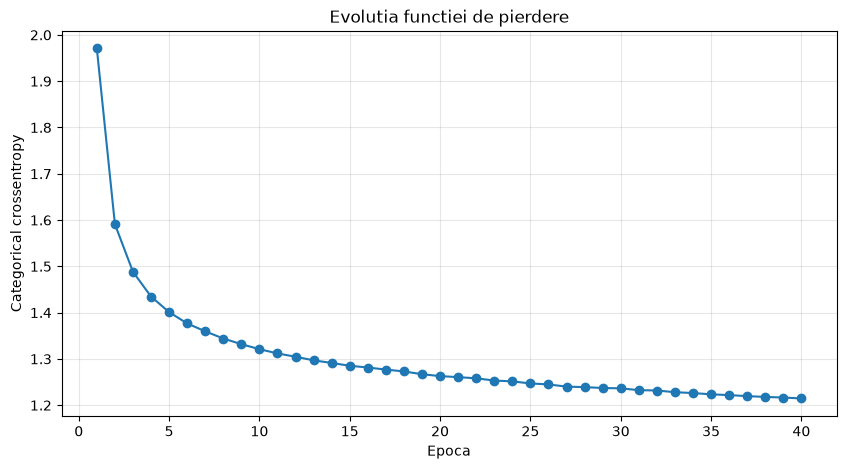

In [11]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(history["loss"]) + 1), history["loss"], marker="o")
plt.title("Evolutia functiei de pierdere")
plt.xlabel("Epoca")
plt.ylabel("Categorical crossentropy")
plt.grid(True, alpha=0.3)
plt.show()

## Pasul 12: Generarea finala de text

Dupa antrenare, generam texte mai lungi (500–1000 de caractere) pornind de la seed-uri alese manual.

Incercati seed-uri care:

- incep la mijlocul unei propozitii;
- contin un cuvant frecvent (de exemplu `the`, `man`, `truth`);
- provin din zone diferite ale corpusului.

Comparati rezultatele pentru temperaturi diferite si notati diferentele de coerenta si repetitivitate.

In [12]:
seeds = [
    text[1000 : 1000 + SEQ_LEN],
    text[100000 : 100000 + SEQ_LEN],
    text[300000 : 300000 + SEQ_LEN],
]

for seed in seeds:
    print("=" * 70)
    print(f'SEED: "{seed}"')
    print("=" * 70)
    for temperature in TEMPERATURES:
        generated = generate_text(model, seed, length=500, temperature=temperature)
        print(f"\n--- Temperatura: {temperature} ---")
        print(generated)
    print()

SEED: "te philosophical edifices as the dogmati"

--- Temperatura: 0.2 ---
ng that the exercise that the conceptions of the self-contradiction of the self-conception of the same too hithes to the problem of the same time to the self-conception of the provesting of the self-conception of the same time to the sentiments of the suppore the streming the sentiments of the self-conceptions of the principle of the principle of the such a strength of the reason of the great strength of the soul of the self-provest and the sention of the conception of the same time to the senti

--- Temperatura: 0.5 ---
ng and ears of the self-problem of the certain to the whole extent the self-ageness of the interest that the conscience, they does not the more interest them to the definite and dear the world of the and to be absolutely the desire that the end the future, that the soul and in the positions of a stremote of the common of the day of the more than the error of religion and faith. 2[). in the insti

## Pasul 13: Salvarea si reincarcarea modelului

Salvam modelul antrenat in formatul nativ Keras (`.keras`), impreuna cu vocabularul, pentru a putea relua generarea fara reantrenare.

Vocabularul trebuie salvat separat, deoarece maparea caracter-index este specifica corpusului.

In [ ]:
import json

MODEL_PATH = "lstm_char_model.keras"
VOCAB_PATH = "vocab.json"

model.save(MODEL_PATH)

In [13]:
with open(VOCAB_PATH, "w", encoding="utf-8") as f:
    json.dump(
        {
            "chars": chars,
            "seq_len": SEQ_LEN,
            "vocab_size": vocab_size,
        },
        f,
        ensure_ascii=False,
        indent=2,
    )

print(f"Model salvat in: {MODEL_PATH}")
print(f"Vocabular salvat in: {VOCAB_PATH}")

Model salvat in: lstm_char_model.keras
Vocabular salvat in: vocab.json


In [14]:
# Reincarcarea modelului si a vocabularului
loaded_model = keras.models.load_model(MODEL_PATH)

with open(VOCAB_PATH, "r", encoding="utf-8") as f:
    vocab_data = json.load(f)

chars = vocab_data["chars"]
vocab_size = vocab_data["vocab_size"]
char_to_idx = {ch: i for i, ch in enumerate(chars)}
idx_to_char = {i: ch for i, ch in enumerate(chars)}

print("Model reincarcat cu succes.")
print(f"Vocabular: {vocab_size} caractere, SEQ_LEN = {vocab_data['seq_len']}")

Model reincarcat cu succes.
Vocabular: 52 caractere, SEQ_LEN = 40


## Concluzii

Am construit un generator de text caracter-cu-caracter folosind un model LSTM. Am parcurs intregul flux: incarcarea si curatarea corpusului, construirea vocabularului, vectorizarea, definirea arhitecturii, antrenarea, generarea cu temperatura si persistenta modelului.

Principala concluzie este ca un LSTM invata foarte bine structura locala a limbajului (ortografie, cuvinte frecvente, punctuatie), dar coerenta pe termen lung ramane limitata. Aceasta limitare este unul dintre motivele pentru care modelele moderne folosesc mecanisme de atentie si arhitecturi Transformer.